原始数据：
   Age  Annual Salary  Weekly hours                    Education
0   72       160000.0          40.0  Bachelor's degree or higher
1   72       100000.0          50.0  Bachelor's degree or higher
2   31       120000.0          40.0  Bachelor's degree or higher
3   28        45000.0          40.0  Bachelor's degree or higher
4   54        85000.0          40.0  Bachelor's degree or higher


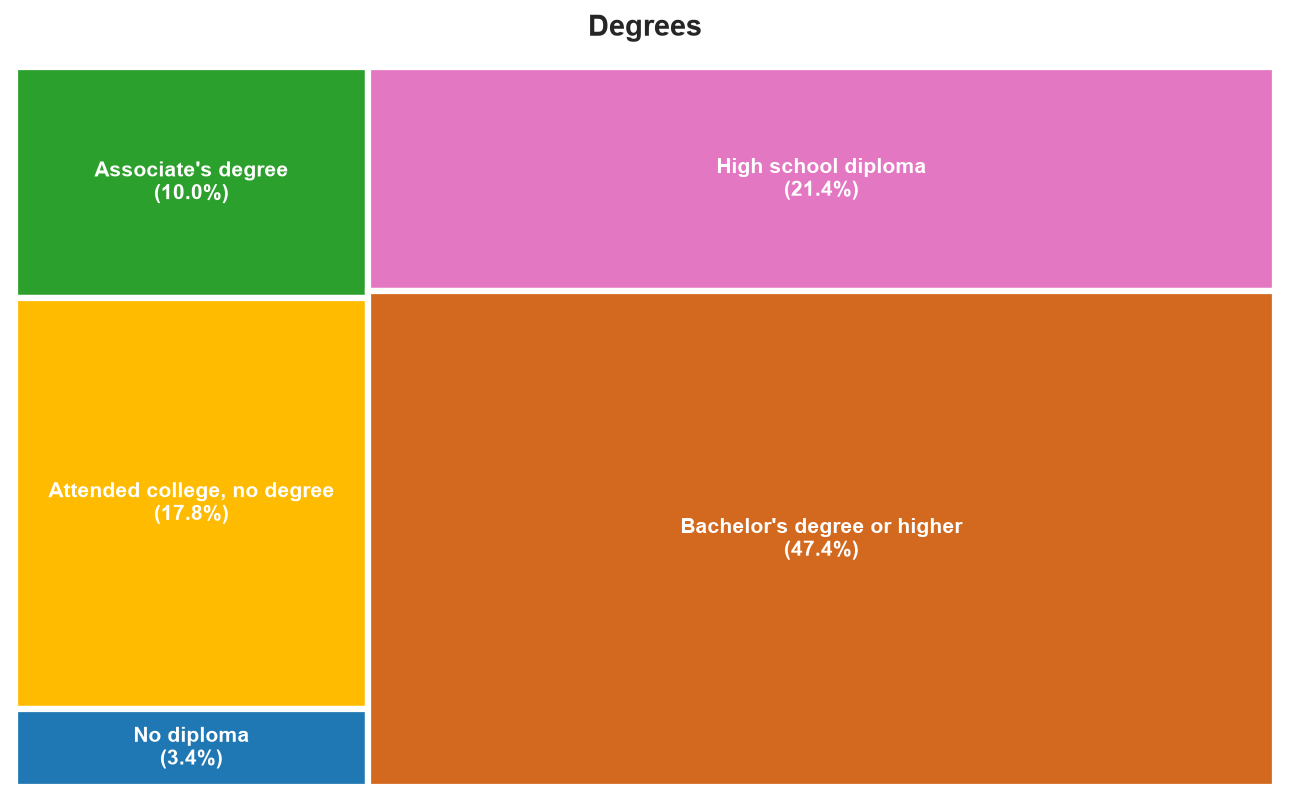

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

# 01: Use pandas to read the age_salary_hours.csv dataset
data = pd.read_csv("age_salary_hours.csv")

print("原始数据：")
print(data.head())

# 02: Use a tree map to visualize the percentages for each education type.

import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

left_ratio = 0.28
right_ratio = 0.72

left_items = [
    ("Associate's degree", 10.0, '#2ca02c'),
    ("Attended college, no degree", 17.8, '#ffbb00'),
    ("No diploma", 3.4, '#1f77b4')
]
right_items = [
    ("High school diploma", 21.4, '#e377c2'),
    ("Bachelor's degree or higher", 47.4, '#d2691e')
]

left_total = sum([item[1] for item in left_items])   # 31.2%
right_total = sum([item[1] for item in right_items]) # 68.8%

current_y = 1.0
for (label, pct, color) in left_items:
    h = pct / left_total * 1.0
    current_y -= h 
    ax.add_patch(patches.Rectangle((0.0, current_y), left_ratio, h, 
                                   facecolor=color, edgecolor='white', linewidth=3))
    ax.text(0.0 + left_ratio/2, current_y + h/2, f"{label}\n({pct}%)", 
            ha='center', va='center', color='white', fontsize=10, fontweight='bold', fontfamily='sans-serif')

current_y = 1.0
for (label, pct, color) in right_items:
    h = pct / right_total * 1.0
    current_y -= h
    ax.add_patch(patches.Rectangle((left_ratio, current_y), right_ratio, h, 
                                   facecolor=color, edgecolor='white', linewidth=3))
    ax.text(left_ratio + right_ratio/2, current_y + h/2, f"{label}\n({pct}%)", 
            ha='center', va='center', color='white', fontsize=10, fontweight='bold', fontfamily='sans-serif')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
plt.title('Degrees', fontsize=14, fontweight='bold', pad=15)

plt.subplots_adjust(left=0.08, right=0.92, bottom=0.08, top=0.88)

plt.show()

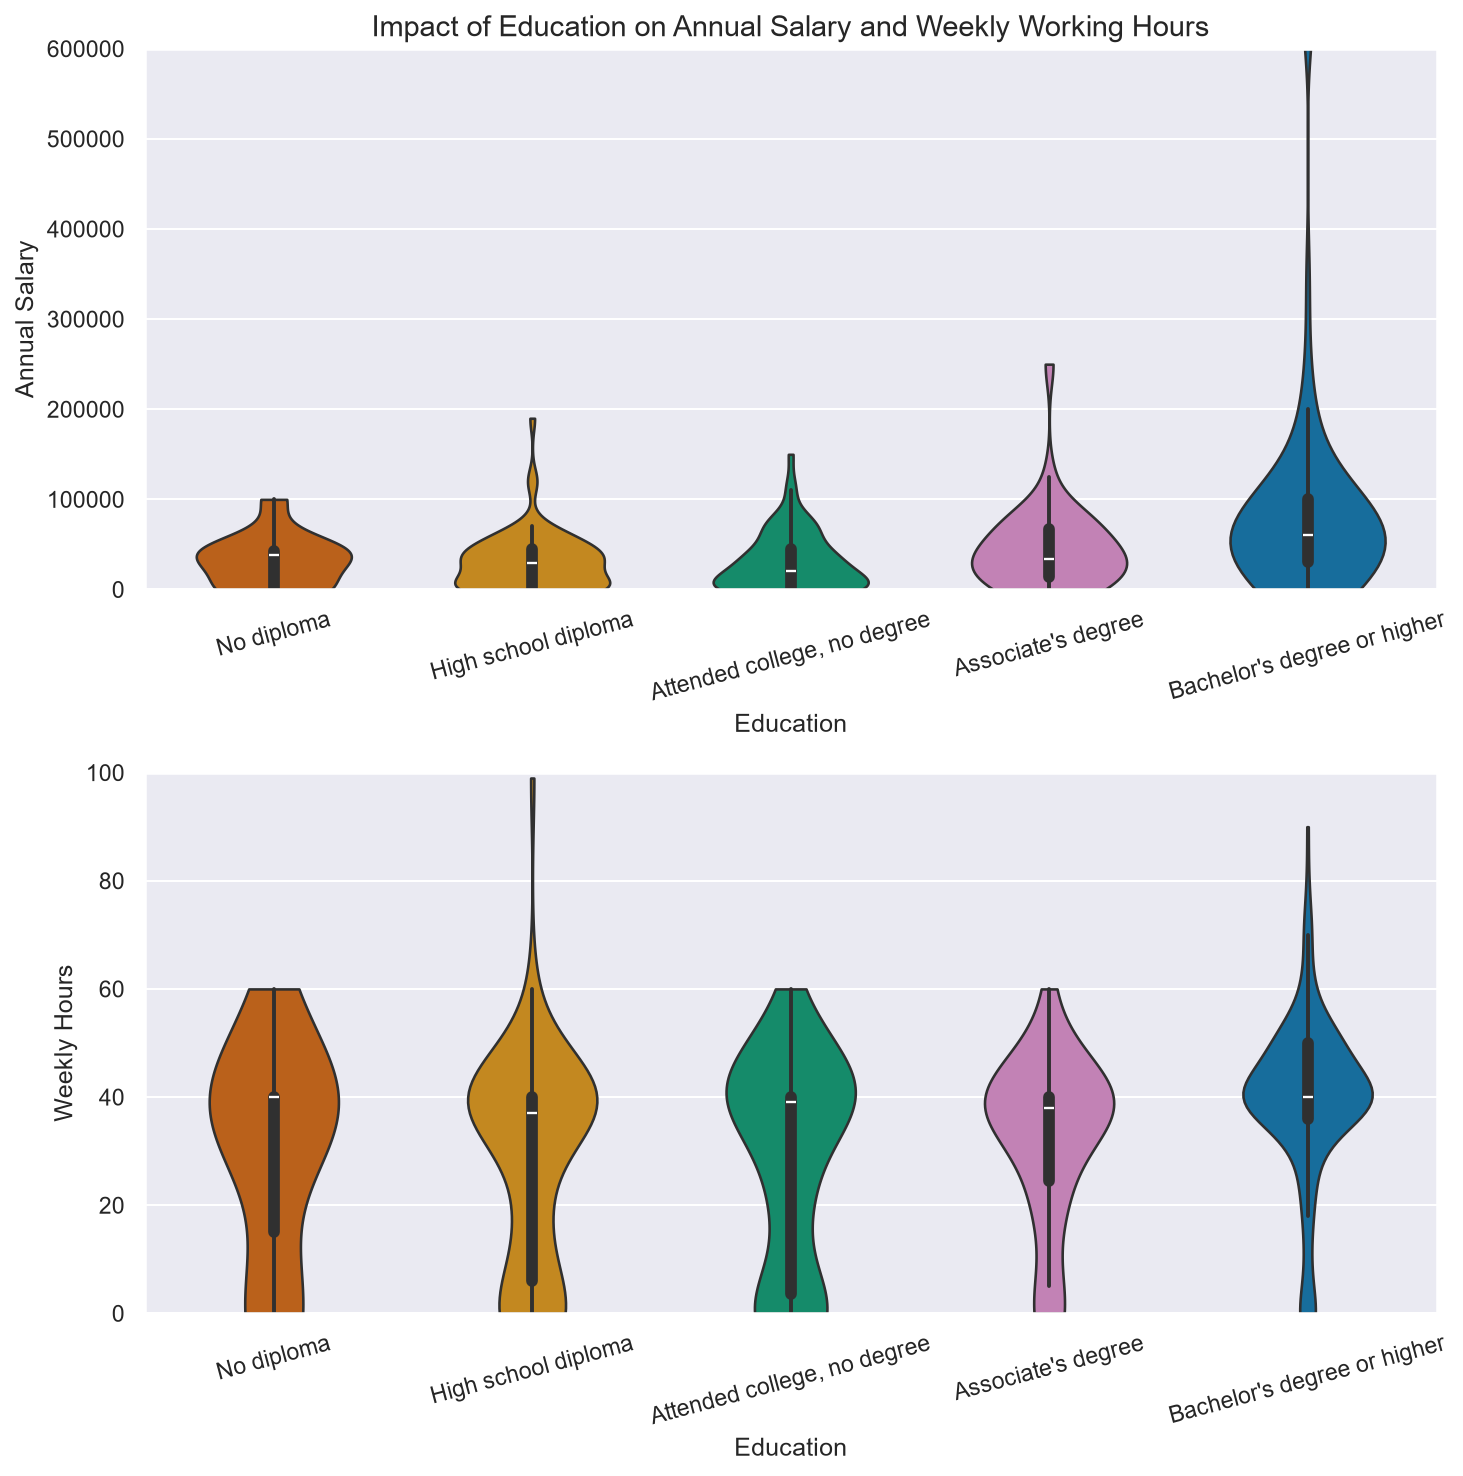

In [37]:
# 03: Create a subplot with two rows to visualize two violin plots for the annual salary and weekly working hours, respectively.

filtered_data = data[data['Age'] < 65].copy()

edu_order = [
    'No diploma', 
    'High school diploma', 
    'Attended college, no degree', 
    'Associate\'s degree', 
    'Bachelor\'s degree or higher'
]

fig, axes = plt.subplots(2, 1, figsize=(10, 10), dpi=150, sharex=False)

sns.set_theme(style="darkgrid")

sns.violinplot(x='Education', y='Annual Salary', data=filtered_data, 
               ax=axes[0], 
               order=edu_order, 
               hue='Education', 
               palette='colorblind', 
               legend=False,
               cut=0,
               width=0.6)

axes[0].set_ylim(0, 600000) 

axes[0].set_title('Impact of Education on Annual Salary and Weekly Working Hours', fontsize=14)
axes[0].set_xlabel('Education', fontsize=12)  # 【关键修复】：为上方图也添加 X 轴标签
axes[0].set_ylabel('Annual Salary', fontsize=12)

axes[0].tick_params(axis='x', rotation=15)

sns.violinplot(x='Education', y='Weekly hours', data=filtered_data, 
               ax=axes[1], 
               order=edu_order, 
               hue='Education', 
               palette='colorblind', 
               legend=False,
               cut=0,
               width=0.5)

axes[1].set_ylim(0, 100) 

axes[1].set_xlabel('Education', fontsize=12)
axes[1].set_ylabel('Weekly Hours', fontsize=12)

axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()

plt.show()